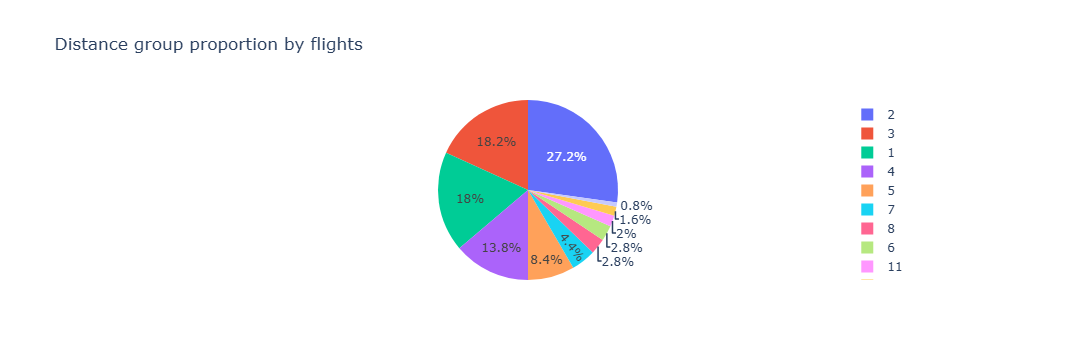

In [1]:
# 导入库
import pandas as pd                 # 表格处理
import plotly.express as px         # 画图（饼图等）
import dash                         # Dash：用纯 Python 写网页仪表盘
from dash import dcc                # dcc = Dash 的"核心组件"（图表 dcc.Graph、输入框 dcc.Input 等）
from dash import html               # html = 用 Python 写 HTML 标签（H1、P、Div 等）
from dash.dependencies import Input, Output   # 回调要用：Input=输入、Output=输出

# 读取"航空公司准点"数据（本地文件），并随机抽 500 行做演示
airline_data = pd.read_csv('Datasets/airline_data.csv',
                           encoding='ISO-8859-1',
                           dtype={'Div1Airport': str, 'Div1TailNum': str,
                                  'Div2Airport': str, 'Div2TailNum': str})

# random_state=42 → 每次抽样结果都一样，方便复现
data = airline_data.sample(n=500, random_state=42)

# 生成饼图：每个"距离组"（每 250 英里一个区间）占多少航班
fig = px.pie(data, values='Flights', names='DistanceGroup',
             title='Distance group proportion by flights')

# 先把这张图单独显示出来看看（仪表盘里要放的就是它）
fig.show()

In [2]:
# 创建一个 Dash 应用
app = dash.Dash(__name__)

# 设置应用布局：整张页面的"骨架"
#   html.Div   → 容器（相当于网页里的 <div>）
#   html.H1    → 一级标题；style 里设：居中、深棕色 #503D36、字号 40
#   html.P     → 段落文字；style 里设：居中、橙色 #F57241
#   dcc.Graph  → 放图表的组件，figure=fig 就是把上面那张饼图放进来
app.layout = html.Div(children=[
    html.H1('Airline Dashboard',
            style={'textAlign': 'center', 'color': '#503D36', 'font-size': 40}),
    html.P('Proportion of distance group (250 mile distance interval group) by flights.',
           style={'textAlign': 'center', 'color': '#F57241'}),
    dcc.Graph(figure=fig),
])

print('Dash 应用与布局已创建完成！')
print('页面组件顺序：', [type(c).__name__ for c in app.layout.children])

Dash 应用与布局已创建完成！
页面组件顺序： ['H1', 'P', 'Graph']


In [3]:
# 真正的 .py 脚本里：在终端执行 python dash_basics.py，然后浏览器打开提示的端口
# 在 notebook 里：用 jupyter_mode='inline' 直接在单元格下方启动预览
try:
    app.run(jupyter_mode='inline')
    print('Dash 应用已启动（notebook 内联模式）。')
    print('点击上方输出里的链接即可打开仪表盘。')
except Exception as e:
    print('内联启动受限（不影响代码本身正确性）：', e)

# 停止运行中的应用：在终端按 Ctrl + C

Dash 应用已启动（notebook 内联模式）。
点击上方输出里的链接即可打开仪表盘。


In [6]:
# 练习：修改标题文字与字号 
# 只需要把 H1 的文本和 font-size 改掉，其他不动
app.layout = html.Div(children=[
    html.H1('Airline On-time Performance Dashboard',
            style={'textAlign': 'center', 'color': '#503D36', 'font-size': 50}),
    html.P('Proportion of distance group (250 mile distance interval group) by flights.',
           style={'textAlign': 'center', 'color': '#F57241'}),
    dcc.Graph(figure=fig),
])

print('新标题：', app.layout.children[0].children)

新标题： Airline On-time Performance Dashboard
